In [2]:
# Cell 1 — Imports and model configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DT, SIM_TIME,
    VEHICLE_LENGTH, MIN_GAP,
    DESIRED_GAP,
    HDV_ACCEL_MIN, HDV_ACCEL_MAX, HDV_SPEED_MAX,
    PEDESTRIAN_TIME, PEDESTRIAN_POSITION,
    PEDESTRIAN_DURATION, PEDESTRIAN_WARNING_DURATION,
    PEDESTRIAN_HDV_SAFE_DISTANCE,
    PEDESTRIAN_HDV_COMFORT_BRAKE,
)

from src.dynamics import calculate_gap, HDVDynamics
from src.simulation_without_ped import simulate
from src.pedestrian import (
    X_STOP,
    MODE_FREE,
    MODE_STOPPING,
    MODE_COMMITTED,
)

MODE_NAMES = {
    MODE_FREE: "FREE",
    MODE_STOPPING: "STOPPING",
    MODE_COMMITTED: "COMMITTED",
}

T_WARNING_START = PEDESTRIAN_TIME - PEDESTRIAN_WARNING_DURATION
T_PEDESTRIAN_END = PEDESTRIAN_TIME + PEDESTRIAN_DURATION

FIG_WIDTH = 12

print(f"DT = {DT} s")
print(f"Simulation time = {SIM_TIME} s")
print(f"Vehicle length = {VEHICLE_LENGTH} m")
print(f"Minimum gap = {MIN_GAP} m")
print(f"Desired HDV gap = {DESIRED_GAP} m")
print()
print(f"Pedestrian warning: {T_WARNING_START:.1f}–{PEDESTRIAN_TIME:.1f} s")
print(f"Pedestrian active:  {PEDESTRIAN_TIME:.1f}–{T_PEDESTRIAN_END:.1f} s")
print(f"Pedestrian position: {PEDESTRIAN_POSITION:.1f} m")
print(f"HDV stop target: {X_STOP:.1f} m")


DT = 0.1 s
Simulation time = 60.0 s
Vehicle length = 4.5 m
Minimum gap = 2.0 m
Desired HDV gap = 10.0 m

Pedestrian warning: 17.0–20.0 s
Pedestrian active:  20.0–30.0 s
Pedestrian position: 400.0 m
HDV stop target: 395.0 m


In [3]:
# Cell 2 — Load the initial traffic

from src.dataloader import load_data

df = load_data()

print("Initial traffic configuration:")
display(df)

print(f"Number of vehicles: {len(df)}")
print("Vehicle types:")
print(df["type"].value_counts())


Initial traffic configuration:


,vehicle_id,position_m,speed_mps,type
0,0,199.50,13.83,HDV
1,1,187.52,15.04,HDV
2,2,172.36,17.25,HDV
3,3,157.54,16.32,HDV
4,4,141.48,14.91,HDV
5,5,127.20,18.12,HDV
6,6,112.52,13.39,HDV
7,7,101.46,14.92,AV
8,8,86.12,15.66,HDV
9,9,72.26,16.56,HDV


Number of vehicles: 15
Vehicle types:
type
HDV    11
AV      4
Name: count, dtype: int64


In [4]:
# Cell 3 — Initial gaps and normal HDV accelerations

df["gap_m"] = np.nan
df["initial_accel_mps2"] = np.nan

for i in range(1, len(df)):
    df.loc[i, "gap_m"] = calculate_gap(
        df.loc[i - 1, "position_m"],
        df.loc[i, "position_m"]
    )

    # The all-HDV simulation uses the HDV car-following model for followers.
    df.loc[i, "initial_accel_mps2"] = HDVDynamics.calculate_acceleration(
        df.loc[i, "speed_mps"],
        df.loc[i - 1, "speed_mps"],
        df.loc[i, "gap_m"]
    )

display(df[
    ["vehicle_id", "type", "position_m", "speed_mps",
     "gap_m", "initial_accel_mps2"]
])

hdv_acc = df["initial_accel_mps2"].dropna()
print()
print(f"Initial follower acceleration range: "
      f"{hdv_acc.min():.2f} to {hdv_acc.max():.2f} m/s²")


,vehicle_id,type,position_m,speed_mps,gap_m,initial_accel_mps2
0,0,HDV,199.50,13.83,NaN,NaN
1,1,HDV,187.52,15.04,7.48,-1.109
2,2,HDV,172.36,17.25,10.66,-0.973
3,3,HDV,157.54,16.32,10.32,0.529
4,4,HDV,141.48,14.91,11.56,1.017
5,5,HDV,127.20,18.12,9.78,-1.649
6,6,HDV,112.52,13.39,10.18,2.401
7,7,AV,101.46,14.92,6.56,-1.453
8,8,HDV,86.12,15.66,10.84,-0.202
9,9,HDV,72.26,16.56,9.36,-0.578



Initial follower acceleration range: -1.65 to 2.71 m/s²


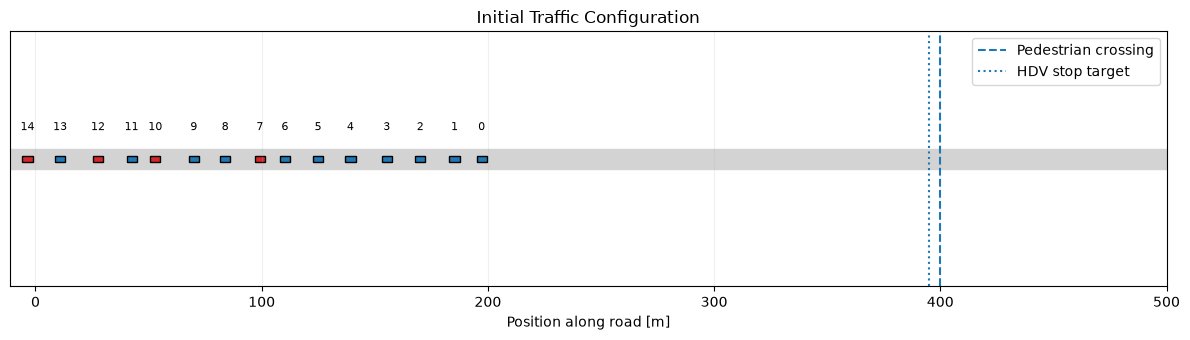

In [5]:
# Cell 4 — Initial traffic scene

VEHICLE_HEIGHT = 0.09
ROAD_Y = 0.0
ROAD_HEIGHT = 0.2 + VEHICLE_HEIGHT

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.5))

road_left = df["position_m"].min() - 10
#road_right = df["position_m"].max() + 10
road_right = 500

ax.add_patch(
    plt.Rectangle(
        (road_left, -ROAD_HEIGHT / 2),
        road_right - road_left,
        ROAD_HEIGHT,
        facecolor="lightgray",
        edgecolor="lightgray",
        linewidth=1.0
    )
)

for _, row in df.iterrows():
    x = row["position_m"]
    facecolor = "tab:red" if row["type"] == "AV" else "tab:blue"
    ax.add_patch(
        plt.Rectangle(
            (x - VEHICLE_LENGTH, ROAD_Y - VEHICLE_HEIGHT / 2),
            VEHICLE_LENGTH,
            VEHICLE_HEIGHT,
            facecolor=facecolor,
            edgecolor="black",
            linewidth=1.0
        )
    )

    ax.text(
        x - VEHICLE_LENGTH / 2,
        VEHICLE_HEIGHT / 2 + 0.12,
        f"{int(row['vehicle_id'])}\n",
        ha="center",
        va="bottom",
        fontsize=8
    )

ax.axvline(PEDESTRIAN_POSITION, linestyle="--", linewidth=1.5,
           label="Pedestrian crossing")
ax.axvline(X_STOP, linestyle=":", linewidth=1.5,
           label="HDV stop target")

ax.set_xlim(road_left, road_right)
ax.set_ylim(-1.8, 1.8)
ax.set_xlabel("Position along road [m]")
ax.set_yticks([])
ax.set_title("Initial Traffic Configuration")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [6]:
# Cell 5 — Run the all-HDV simulation

results = simulate(df)

time = results["time"]
positions = results["positions"]
speeds = results["speeds"]
accelerations = results["accelerations"]
gaps = results["gaps"]

vehicle_types = results["vehicle_types"]
pedestrian_state = results["pedestrian_state"]
pedestrian_accelerations = results["pedestrian_accelerations"]
modes = results["modes"]
wall_hits = results["wall_hits"]
infeasible_events = results["infeasible_events"]

print(f"Simulation duration: {time[-1]:.1f} s")
print(f"Number of vehicles: {positions.shape[1]}")
print(f"Number of time steps: {len(time)}")
print("Scenario: all vehicles are simulated with HDV dynamics.")


TypeError: only integer scalar arrays can be converted to a scalar index

In [ ]:
# Cell 6 — Basic simulation summary

print("===== SIMULATION SUMMARY =====")
print(f"Final simulation time: {time[-1]:.1f} s")
print(f"Vehicles: {positions.shape[1]}")
print(f"Minimum simulated gap: {np.nanmin(gaps):.2f} m")
print(f"Maximum simulated speed: {np.max(speeds):.2f} m/s")
print(f"Minimum simulated speed: {np.min(speeds):.2f} m/s")
print(f"Number of wall hits: {int(np.sum(wall_hits))}")
print(f"Number of recorded infeasible events: {len(infeasible_events)}")


In [ ]:
# Cell 7 — Check the pedestrian timeline

print("===== PEDESTRIAN TIMELINE =====")

for state in ["none", "warning", "active", "cleared"]:
    idx = np.where(pedestrian_state == state)[0]

    if len(idx):
        print(
            f"{state:>8}: "
            f"{time[idx[0]]:.1f} s to {time[idx[-1]]:.1f} s"
        )

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 2.5))

state_numeric = {
    "none": 0,
    "warning": 1,
    "active": 2,
    "cleared": 3,
}

y = np.array([state_numeric[s] for s in pedestrian_state])

ax.step(time, y, where="post", linewidth=2)
ax.set_yticks(list(state_numeric.values()))
ax.set_yticklabels(list(state_numeric.keys()))
ax.set_xlabel("Time [s]")
ax.set_ylabel("Pedestrian state")
ax.set_title("Pedestrian State Over Time")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 8 — Vehicle position trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(positions.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    ax.plot(time, positions[:, i], linewidth=1.4, label=f"Vehicle {vehicle_id}")

ax.axhline(PEDESTRIAN_POSITION, linestyle="--", linewidth=1.5,
           label="Pedestrian crossing")
ax.axhline(X_STOP, linestyle=":", linewidth=1.5,
           label="HDV stop target")

ax.axvspan(T_WARNING_START, PEDESTRIAN_TIME, alpha=0.12,
           label="Warning period")
ax.axvspan(PEDESTRIAN_TIME, T_PEDESTRIAN_END, alpha=0.07,
           label="Pedestrian active")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Vehicle front-bumper position [m]")
ax.set_title("HDV Position Trajectories")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 9 — Vehicle speed trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(speeds.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    ax.plot(time, speeds[:, i], linewidth=1.4, label=f"Vehicle {vehicle_id}")

ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2,
           label="Warning starts")
ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2,
           label="Pedestrian appears")
ax.axvline(T_PEDESTRIAN_END, linestyle="-.", linewidth=1.2,
           label="Pedestrian clears")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("HDV Speed Trajectories")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 10 — Vehicle acceleration trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(accelerations.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    ax.plot(time, accelerations[:, i], linewidth=1.2, label=f"Vehicle {vehicle_id}")

ax.axhline(0.0, linewidth=1.0)
ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2)
ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Acceleration [m/s²]")
ax.set_title("HDV Acceleration Trajectories")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 11 — Inter-vehicle gaps

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(1, gaps.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    ax.plot(time, gaps[:, i], linewidth=1.3, label=f"Vehicle {vehicle_id}")

ax.axhline(DESIRED_GAP, linestyle="--", linewidth=1.3,
           label=f"Desired gap = {DESIRED_GAP:.1f} m")
ax.axhline(MIN_GAP, linestyle=":", linewidth=1.3,
           label=f"Minimum gap = {MIN_GAP:.1f} m")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Bumper-to-bumper gap [m]")
ax.set_title("HDV Following Gaps")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 12 — Direct pedestrian response of each HDV

print("===== DIRECT PEDESTRIAN RESPONSE =====")

response_rows = []

for i in range(positions.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    mask = np.isfinite(pedestrian_accelerations[:, i])

    if np.any(mask):
        idx = np.where(mask)[0]
        response_rows.append({
            "vehicle_id": vehicle_id,
            "first_response_s": time[idx[0]],
            "last_response_s": time[idx[-1]],
            "position_at_first_response_m": positions[idx[0], i],
            "speed_at_first_response_mps": speeds[idx[0], i],
            "minimum_pedestrian_accel_mps2": np.min(
                pedestrian_accelerations[idx, i]
            ),
        })
    else:
        response_rows.append({
            "vehicle_id": vehicle_id,
            "first_response_s": np.nan,
            "last_response_s": np.nan,
            "position_at_first_response_m": np.nan,
            "speed_at_first_response_mps": np.nan,
            "minimum_pedestrian_accel_mps2": np.nan,
        })

response_df = pd.DataFrame(response_rows)
display(response_df)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(positions.shape[1]):
    mask = np.isfinite(pedestrian_accelerations[:, i])

    if np.any(mask):
        vehicle_id = int(df.iloc[i]["vehicle_id"])
        ax.plot(
            time[mask],
            pedestrian_accelerations[mask, i],
            linewidth=1.5,
            label=f"Vehicle {vehicle_id}"
        )

ax.axhline(-PEDESTRIAN_HDV_COMFORT_BRAKE, linestyle="--", linewidth=1.2,
           label="Comfort-braking threshold")
ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2)
ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Pedestrian braking command [m/s²]")
ax.set_title("HDV Pedestrian Braking Commands")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
# Cell 13 — HDV pedestrian-driving modes

mode_df = pd.DataFrame(
    modes,
    index=time,
    columns=[int(v) for v in df["vehicle_id"]]
)

print("Mode values:")
print(MODE_NAMES)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

image = ax.imshow(
    modes.T,
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], -0.5, modes.shape[1] - 0.5],
    interpolation="nearest"
)

cbar = fig.colorbar(image, ax=ax)
cbar.set_ticks([MODE_FREE, MODE_STOPPING, MODE_COMMITTED])
cbar.set_ticklabels([
    MODE_NAMES[MODE_FREE],
    MODE_NAMES[MODE_STOPPING],
    MODE_NAMES[MODE_COMMITTED],
])

ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2)
ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2)

ax.set_yticks(np.arange(modes.shape[1]))
ax.set_yticklabels([int(v) for v in df["vehicle_id"]])
ax.set_xlabel("Time [s]")
ax.set_ylabel("Vehicle ID")
ax.set_title("HDV Pedestrian-Driving Modes")
plt.tight_layout()
plt.show()

print("\nMode changes by vehicle:")
for i in range(modes.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    change_idx = np.where(np.diff(modes[:, i]) != 0)[0] + 1

    if len(change_idx) == 0:
        print(f"Vehicle {vehicle_id}: no mode changes")
    else:
        changes = [
            f"{time[k]:.1f}s: {MODE_NAMES[modes[k-1, i]]} → "
            f"{MODE_NAMES[modes[k, i]]}"
            for k in change_idx
        ]
        print(f"Vehicle {vehicle_id}: " + "; ".join(changes))


In [ ]:
# Cell 14 — Infeasible events

print("===== INFEASIBLE EVENTS =====")

if len(infeasible_events) == 0:
    print("No infeasible events were recorded.")
else:
    event_rows = []

    for event_time, vehicle_index, position, speed in infeasible_events:
        event_rows.append({
            "time_s": event_time,
            "vehicle_index": vehicle_index,
            "vehicle_id": int(df.iloc[vehicle_index]["vehicle_id"]),
            "position_m": position,
            "speed_mps": speed,
        })

    infeasible_df = pd.DataFrame(event_rows)

    print(f"Total recorded infeasible events: {len(infeasible_df)}")
    display(infeasible_df)

    print("Events by vehicle:")
    display(
        infeasible_df.groupby("vehicle_id")
        .agg(
            number_of_events=("time_s", "size"),
            first_event_s=("time_s", "min"),
            last_event_s=("time_s", "max"),
            first_position_m=("position_m", "first"),
            first_speed_mps=("speed_mps", "first"),
        )
        .reset_index()
    )

    # Event timing by vehicle
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))

    for vehicle_id, group in infeasible_df.groupby("vehicle_id"):
        ax.scatter(
            group["time_s"],
            np.full(len(group), vehicle_id),
            marker="x",
            s=45
        )

    ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2,
               label="Warning starts")
    ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2,
               label="Pedestrian appears")

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Vehicle ID")
    ax.set_title("Recorded Infeasible Events")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()


In [ ]:
# Cell 15 — Infeasible events on the position trajectories

if len(infeasible_events) == 0:
    print("No infeasible events to overlay.")
else:
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

    for i in range(positions.shape[1]):
        vehicle_id = int(df.iloc[i]["vehicle_id"])
        ax.plot(time, positions[:, i], linewidth=1.2)

    for event_time, vehicle_index, position, speed in infeasible_events:
        vehicle_id = int(df.iloc[vehicle_index]["vehicle_id"])
        ax.scatter(
            event_time,
            position,
            marker="x",
            s=55
        )
        ax.annotate(
            f"V{vehicle_id}",
            (event_time, position),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax.axhline(PEDESTRIAN_POSITION, linestyle="--", linewidth=1.5,
               label="Pedestrian crossing")
    ax.axhline(X_STOP, linestyle=":", linewidth=1.5,
               label="HDV stop target")

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Vehicle front-bumper position [m]")
    ax.set_title("Infeasible Events Along Vehicle Trajectories")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()


In [ ]:
# Cell 16 — One summary row per vehicle

summary_rows = []

for i in range(positions.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])

    vehicle_gaps = gaps[:, i]
    valid_gaps = vehicle_gaps[np.isfinite(vehicle_gaps)]

    response_mask = np.isfinite(pedestrian_accelerations[:, i])

    vehicle_events = [
        e for e in infeasible_events if e[1] == i
    ]

    summary_rows.append({
        "vehicle_id": vehicle_id,
        "initial_position_m": positions[0, i],
        "initial_speed_mps": speeds[0, i],
        "final_position_m": positions[-1, i],
        "final_speed_mps": speeds[-1, i],
        "minimum_gap_m": np.min(valid_gaps) if len(valid_gaps) else np.nan,
        "first_pedestrian_response_s": (
            time[np.where(response_mask)[0][0]]
            if np.any(response_mask) else np.nan
        ),
        "minimum_pedestrian_accel_mps2": (
            np.min(pedestrian_accelerations[response_mask, i])
            if np.any(response_mask) else np.nan
        ),
        "infeasible_event_count": len(vehicle_events),
        "wall_hit_count": int(np.sum(wall_hits[:, i])),
    })

vehicle_summary = pd.DataFrame(summary_rows)

display(vehicle_summary)
